DECIDE BEFORE YOU LOOK  (write these in a markdown cell first)
  - Which run do you expect to win: A, B, or C?  (C = same network, NOT pretrained)
    * A
  - What accuracy do you expect for each?
    * 0.9687, 0.8456, 0.9328
  - How many validation images is one percentage point?  (153 images -> one image is 0.65 percent.  A difference of 1 or 2 images is NOISE.)
    * about 1.5 images (153 / 100)

RUNS  (one change at a time, 8 epochs each, the same loaders and seed)

Baseline : always predict the more common class.  (Compute the accuracy.)

A : pretrained, only the new fc trains

B : pretrained, layer4 + fc train

C : NOT pretrained (weights=None), everything trains

**DECIDE BEFORE YOU LOOK**
- Expected winner: A (feature extractor).
- Expected accuracy: A 0.9687, B 0.8456, C 0.9328.
- One validation image is 0.65 percent (one percentage point is about 1.5 images). A difference of 1 or 2 images is noise.
- Result: A 0.9608, B 0.9542, C 0.6536. My guess for A was close, for B too low, and for C far too high: a network without pretraining cannot learn this from 244 photos in 8 epochs.

**Part 3**
- S18-1  Transfer learning means taking a model already trained on a big dataset (ImageNet) and reusing its knowledge for a new task. It works with 244 photos because the early layers learned edges and textures on about 1.2 million ImageNet photos, and those are the same for ants and bees.
- S18-2  In the extractor everything is frozen except the new last layer (fc). In fine-tuning the early layers stay frozen, while layer4 and fc are trainable. Fine-tuning needs the smaller learning rate (1e-4 for layer4), so the pretrained features are nudged and not destroyed; the new head can use 1e-3.
- S18-3  Total 11,177,538; trainable in run A 1,026; in run B 8,394,754.
- S18-4  The pretrained weights were trained on inputs normalised with the ImageNet mean and std. Raw values are on a different scale, so the features it computes would be wrong.
- S18-5  The validation images must be the same on every pass. A random crop or flip would make the validation score noisy and not repeatable. Augmentation is for training only.
- S18-6  My expectation was that A would win; the result was that A has the highest number (0.9608), but it is a tie with B (0.9542). C (0.6536) was far behind.
- S18-7  One validation image is 0.65 percent. A and B differ by 0.66 percent (one image), which is a tie, because it is inside the 2 to 3 image noise band.
- S18-8  The extractor stays in model.eval() while training so the BatchNorm layers keep their pretrained running mean and variance. In train mode they would update them, even though the weights are frozen.
- S18-9  Three limits: (1) only 153 validation images, so one image is 0.65 percent and A against B cannot be separated; (2) the best epoch is chosen on the same images we report, and there is no separate test set, so the best-epoch number is optimistic; (3) two easy classes, one seed and only 8 epochs (the scratch run was still improving).
- S18-10 ResNet-18 is a stack of convolution layers, each followed by BatchNorm and ReLU (with shortcut connections), with pooling near the start and end, and one final Linear layer (our new fc) that gives the 2 class scores.

**ANTS OR BEES: TRANSFER LEARNING**

Baseline accuracy: 0.5425

- QUESTION: Can a pretrained ResNet-18 classify 153 validation photos of ants and bees after training on only 244 photos, and does pretraining matter?
- CHECK: Three runs for 8 epochs on the same loaders and seed: the extractor (only the new fc trains), fine-tuning (layer4 + fc) and the same network without pretraining; validation accuracy, best epoch and last epoch.
- FINDING: The extractor reaches 0.9608 (best, epoch 3) and 0.9542 (last), fine-tuning 0.9542, and the scratch run only 0.6536 (majority baseline: 0.5425). Extractor and fine-tuning differ by one image (0.65 percent), a tie. Pretraining is worth about 46 images. The scratch run was still improving at epoch 8.
- DECISION: Use the feature extractor: the same accuracy as fine-tuning within the noise, with 1,026 trainable parameters instead of 8.4 million. Limits: 153 validation images, the best epoch chosen on the same images, no test set.

In [4]:
!wget -q https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -q hymenoptera_data.zip

In [5]:
import copy, numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [6]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                              transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_val = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                            transforms.ToTensor(), transforms.Normalize(mean, std)])
train_ds = datasets.ImageFolder("hymenoptera_data/train", tf_train)
val_ds = datasets.ImageFolder("hymenoptera_data/val", tf_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42))
val_loader = DataLoader(val_ds, batch_size=32)

In [8]:
print(train_ds.classes, len(train_ds), len(val_ds))
print(np.bincount(val_ds.targets))

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)

count = np.bincount(val_ds.targets)
bigger = np.argmax(count)
all_val = len(val_ds)
baseline = count[bigger] / all_val
print("baseline accuracy:", round(baseline, 4))

['ants', 'bees'] 244 153
[70 83]
torch.Size([32, 3, 224, 224]) torch.Size([32])
baseline accuracy: 0.5425


In [12]:
def make_model(mode):
  torch.manual_seed(42)
  if mode == "scratch":
    m = models.resnet18(weights=None)
  else:
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

  if mode == "extractor":
    for p in m.parameters():
      p.requires_grad = False

  m.fc = nn.Linear(m.fc.in_features, 2)

  if mode == "finetune":
    for p in m.parameters():
      p.requires_grad = False
    for p in m.layer4.parameters():
      p.requires_grad = True
    for p in m.fc.parameters():
      p.requires_grad = True
  return m.to(device)


In [13]:
for mode in ["extractor", "finetune", "scratch"]:
  m = make_model(mode)
  print(mode, "trainable:", sum(p.numel() for p in m.parameters() if p.requires_grad),
        "of", sum(p.numel() for p in m.parameters()))

extractor trainable: 1026 of 11177538
finetune trainable: 8394754 of 11177538
scratch trainable: 11177538 of 11177538


In [22]:
def run_epoch(model, loader, loss_fn, opt=None, train=True, frozen=False):
  if train and not frozen:
    model.train()
  else:
    model.eval()
  tot = correct = n = 0
  with torch.set_grad_enabled(train):
    for xb, yb in loader:
      xb, yb = xb.to(device), yb.to(device)
      out = model(xb)
      loss = loss_fn(out, yb)
      if train:
        opt.zero_grad(); loss.backward(); opt.step()
      tot += loss.item() * len(yb)
      correct += (out.argmax(1) == yb).sum().item()
      n += len(yb)
  return tot / n, correct / n

In [23]:
def fit(mode, epochs=8):
  model = make_model(mode)
  if mode == "extractor":
    opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
  elif mode == "finetune":
    opt = torch.optim.Adam([{"params": model.layer4.parameters(), "lr":1e-4},
                            {"params": model.fc.parameters(), "lr":1e-3}])
  else:
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
  loss_fn = nn.CrossEntropyLoss()

  hist, best = [], (0, 0, 1e9)
  for ep in range(1, epochs + 1):
    tl, ta = run_epoch(model, train_loader, loss_fn, opt, True, frozen=(mode == "extractor"))
    vl, va = run_epoch(model, val_loader, loss_fn, None, False)
    hist.append((ep, tl, ta, vl, va))
    if va > best[0]:
      best = (va, ep, vl)
  return best, hist

In [24]:
rows, histories = [], {}
for mode in ["extractor", "finetune", "scratch"]:
  best, hist = fit(mode)
  histories[mode] = hist
  rows.append((mode, best[1], round(best[0], 4), round(hist[-1][4], 4), round(best[2], 4)))
pd.DataFrame(rows, columns=["run", "best epoch", "best val acc", "last val acc", "val loss"])

,run,best epoch,best val acc,last val acc,val loss
0,extractor,3,0.9608,0.9542,0.2059
1,finetune,8,0.9542,0.9542,0.2113
2,scratch,8,0.6536,0.6536,0.6186


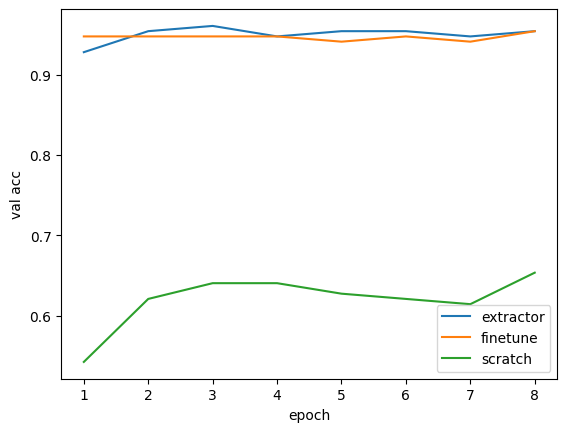

In [25]:
for mode, h in histories.items():
  plt.plot([r[0] for r in h], [r[4] for r in h], label=mode)
plt.xlabel("epoch")
plt.ylabel("val acc")
plt.legend()
plt.show()